<a href="https://colab.research.google.com/github/NadiyaNowshin/Clustering-Dimensionality-Reduction/blob/main/Clustering_%26_Dimensionality_Reduction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings("ignore")

Load the Iris Dataset

In [2]:
# ================================
# LOAD IRIS DATASET
# ================================

iris = load_iris()

X = iris.data
y = iris.target

feature_names = iris.feature_names
target_names = iris.target_names

# Create DataFrame
df = pd.DataFrame(X, columns=feature_names)

# Add actual class for interpretation
df["species"] = y

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Check the dataset

In [3]:
print("Dataset shape:", X.shape)
print("\nFeature names:")
print(feature_names)

print("\nTarget classes:")
print(target_names)

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (150, 4)

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target classes:
['setosa' 'versicolor' 'virginica']

First 5 rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Standardize the Features

In [4]:
# ================================
# STANDARDIZE FEATURES
# ================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("original data shape:",X.shape)
print("scaled data shape:", X_scaled.shape)

original data shape: (150, 4)
scaled data shape: (150, 4)


Elbow Method

In [5]:
# ================================
# ELBOW METHOD
# ================================

inertia = []

K_range = range(1,11)

for k in K_range:

  kmeans = KMeans(
      n_clusters=k,
      random_state=42,
      n_init=10)

  kmeans.fit(X_scaled)

  inertia.append(kmeans.inertia_)

Plot the Elbow Curve

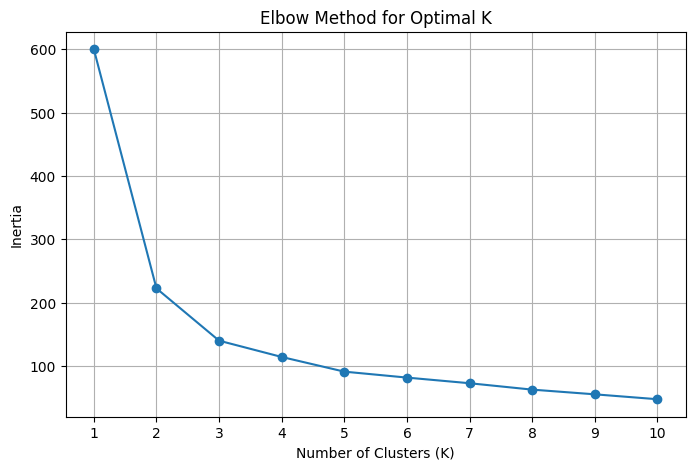

In [6]:
plt.figure(figsize=(8, 5))

plt.plot(K_range, inertia, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")

plt.xticks(K_range)
plt.grid(True)

plt.show()

#Interpretation
Apply K-Means with K = 3

In [7]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("Cluster labels:")
print(kmeans_labels)

Cluster labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


Visualize K-Means Clusters

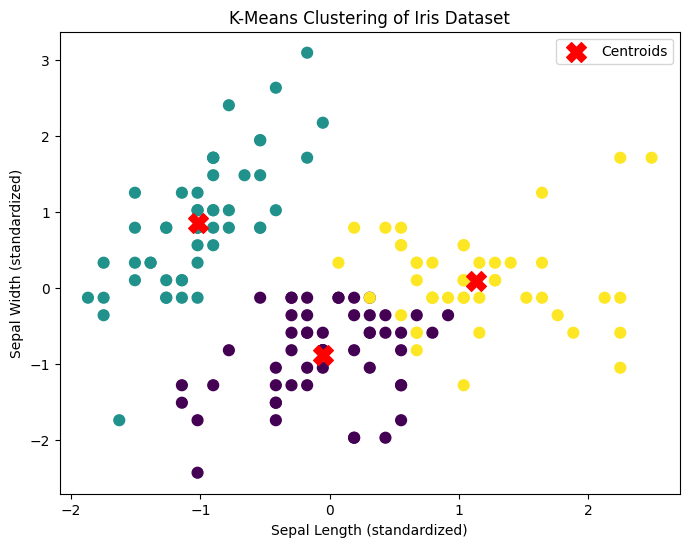

In [8]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=60
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=200,
    color="red",
    label="Centroids"
)

plt.xlabel("Sepal Length (standardized)")
plt.ylabel("Sepal Width (standardized)")
plt.title("K-Means Clustering of Iris Dataset")

plt.legend()
plt.show()

#Principal Component Analysis
Apply PCA

In [9]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("PCA shape:", X_pca.shape)

Original shape: (150, 4)
PCA shape: (150, 2)


Explained Variance Ratio

In [10]:
explained_variance = pca.explained_variance_ratio_

print("Explained Variance Ratio:")
print(explained_variance)

print("\nTotal variance explained by 2 components:", explained_variance.sum())

Explained Variance Ratio:
[0.72962445 0.22850762]

Total variance explained by 2 components: 0.9581320720000166


In [11]:
variance_df = pd.DataFrame({
    "Principal Component" : ["PC1", "PC2"],
    "Explained Variance Ratio": explained_variance,
})

display(variance_df)

,Principal Component,Explained Variance Ratio
0,PC1,0.729624
1,PC2,0.228508


Plot explained variance

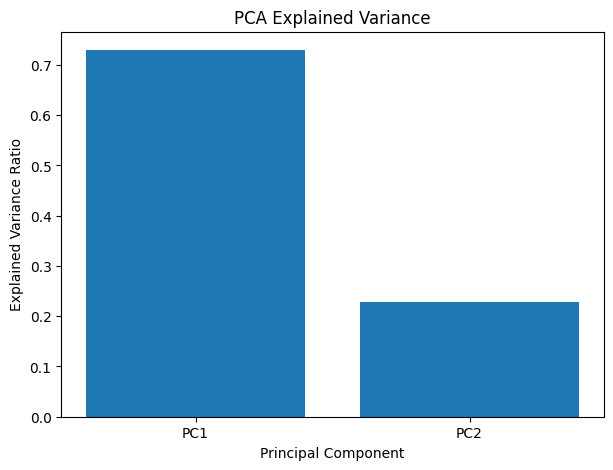

In [12]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["PC1", "PC2"],
    explained_variance
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance")

plt.show()

Plot PCA Components

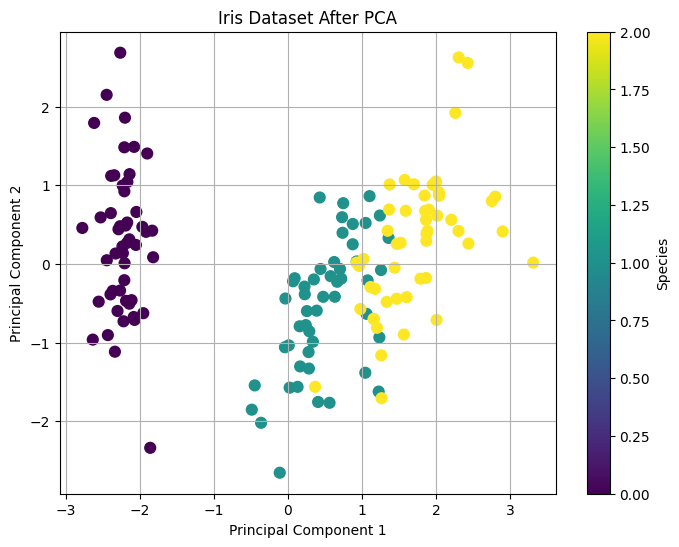

In [13]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=y,
    cmap="viridis",
    s=60
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Iris Dataset After PCA")

plt.colorbar(label="Species")
plt.grid(True)

plt.show()

K-Means on PCA Data

In [14]:
kmeans_pca = KMeans(
  n_clusters = 3,
  random_state = 42,
  n_init = 10
)

pca_labels = kmeans_pca.fit_predict(X_pca)

In [15]:
print("X_pca shape:", X_pca.shape)
print("pca_labels shape:", pca_labels.shape)
print("kmeans_labels shape:", kmeans_labels.shape)

X_pca shape: (150, 2)
pca_labels shape: (150,)
kmeans_labels shape: (150,)


Compare K-Means on original vs PCA data

In [16]:
ari_original = adjusted_rand_score(y, kmeans_labels)
ari_pca = adjusted_rand_score(y, pca_labels)

print("ARI - K-Means on original standardized data:", ari_original)
print("ARI - K-Means on PCA data:", ari_pca)

ARI - K-Means on original standardized data: 0.6201351808870379
ARI - K-Means on PCA data: 0.6201351808870379


In [17]:
silhouette_original = silhouette_score(
    X_scaled,
    kmeans_labels
)

silhouette_pca = silhouette_score(
    X_pca,
    pca_labels
)

print("Silhouette Score - Original data:",
      silhouette_original)

print("Silhouette Score - PCA data:",
      silhouette_pca)

Silhouette Score - Original data: 0.45994823920518635
Silhouette Score - PCA data: 0.5091683341538228


Interpretation

The ARI measures how closely the clustering corresponds to the known Iris species.

The silhouette score measures how well separated the clusters are.

PCA reduces the dimensionality from four features to two while retaining most of the dataset's variance. Therefore, clustering on PCA data can produce results similar to clustering on the original standardized data.

Apply Hierarchical Clustering

In [19]:
hierarchical = AgglomerativeClustering(
    n_clusters = 3,
    linkage = "ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

print("Hierarchical cluster labels:")
print(hierarchical_labels)

Hierarchical cluster labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 2 1 1 1 1 1 1 1 1 0 0 0 2 0 2 0 2 0 2 2 0 2 0 2 0 2 2 2 2 0 0 0 0
 0 0 0 0 0 2 2 2 2 0 2 0 0 2 2 2 2 0 2 2 2 2 2 0 2 2 0 0 0 0 0 0 2 0 0 0 0
 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]


Create Dendrogram

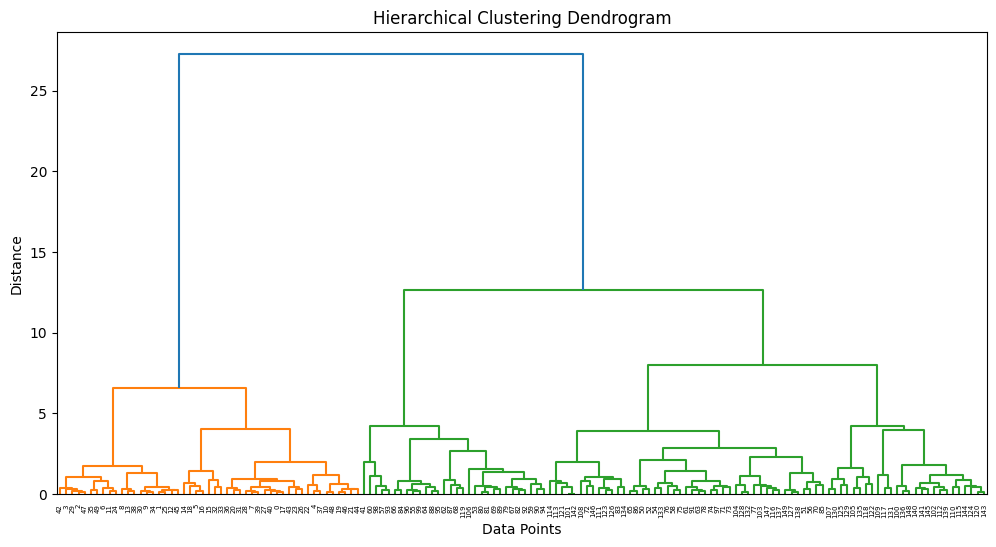

In [22]:
linkage_matrix = linkage(
    X_scaled,
    method="ward"
)

plt.figure(figsize=(12, 6))

dendrogram(
    linkage_matrix,
    truncate_mode=None
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")

plt.show()

Visualize Hierarchical Clusters

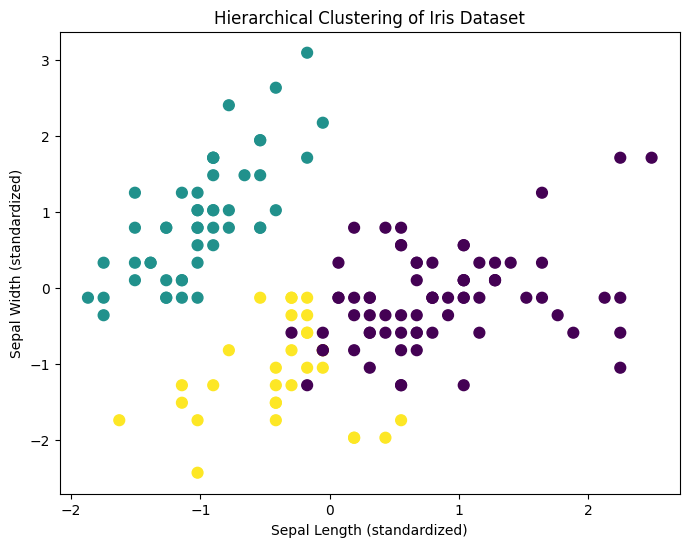

In [23]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=hierarchical_labels,
    cmap="viridis",
    s=60
)

plt.xlabel("Sepal Length (standardized)")
plt.ylabel("Sepal Width (standardized)")
plt.title("Hierarchical Clustering of Iris Dataset")

plt.show()

Compare Hierarchical Clustering with K-Means

In [24]:
ari_kmeans = adjusted_rand_score(
    y,
    kmeans_labels
)

ari_hierarchical = adjusted_rand_score(
    y,
    hierarchical_labels
)

print("K-Means ARI:", ari_kmeans)
print("Hierarchical Clustering ARI:", ari_hierarchical)

K-Means ARI: 0.6201351808870379
Hierarchical Clustering ARI: 0.6153229932145449


In [25]:
ari_kmeans_hierarchical = adjusted_rand_score(
    kmeans_labels,
    hierarchical_labels
)

print(
    "Agreement between K-Means and Hierarchical Clustering:",
    ari_kmeans_hierarchical
)

Agreement between K-Means and Hierarchical Clustering: 0.6255455129518299


Apply DBSCAN

In [29]:
dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_scaled)

print("DBSCAN labels:")
print(dbscan_labels)

150
DBSCAN labels:
[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1 -1  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0 -1 -1  0  0  0  0  0  0  0 -1  0  0  0  0  0  0
  0  0  1  1  1  1  1  1 -1 -1  1 -1 -1  1 -1  1  1  1  1  1 -1  1  1  1
 -1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1 -1  1  1  1  1  1 -1  1  1
  1  1 -1  1 -1  1  1  1  1 -1 -1 -1 -1 -1  1  1  1  1 -1  1  1 -1 -1 -1
  1  1 -1  1  1 -1  1  1  1 -1 -1 -1  1  1  1 -1 -1  1  1  1  1  1  1  1
  1  1  1  1 -1  1]


Experiment with Different Parameters

In [28]:
parameters = [
    (0.3, 5),
    (0.4, 5),
    (0.5, 5),
    (0.6, 5),
    (0.7, 5),
    (0.5, 10)
]

results = []

for eps, min_samples in parameters:

    db = DBSCAN(
        eps=eps,
        min_samples=min_samples
    )

    labels = db.fit_predict(X_scaled)

    n_clusters = len(
        set(labels)
        - {-1}
    )

    n_noise = np.sum(
        labels == -1
    )

    results.append([
        eps,
        min_samples,
        n_clusters,
        n_noise
    ])

dbscan_results = pd.DataFrame(results,columns=[
        "eps",
        "min_samples",
        "Number of Clusters",
        "Number of Noise Points"
    ]
)

display(dbscan_results)

,eps,min_samples,Number of Clusters,Number of Noise Points
0,0.3,5,3,120
1,0.4,5,6,66
2,0.5,5,2,34
3,0.6,5,2,26
4,0.7,5,2,6
5,0.5,10,3,89


Select DBSCAN Parameters

In [30]:
dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_scaled)

print("Unique labels:", np.unique(dbscan_labels))

print(
    "Number of clusters:",
    len(set(dbscan_labels) - {-1})
)

print(
    "Number of noise points:",
    np.sum(dbscan_labels == -1)
)

Unique labels: [-1  0  1]
Number of clusters: 2
Number of noise points: 34


Plot DBSCAN Clusters

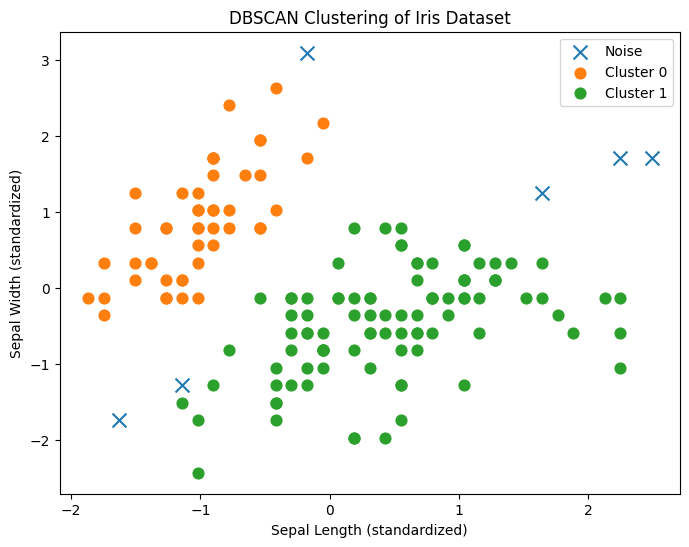

In [33]:
plt.figure(figsize=(8, 6))

unique_labels = np.unique(dbscan_labels)

for label in unique_labels:

    if label == -1:
        # Noise
        mask = dbscan_labels == label

        plt.scatter(
            X_scaled[mask, 0],
            X_scaled[mask, 1],
            marker="x",
            s=100,
            label="Noise"
        )

    else:
        mask = dbscan_labels == label

        plt.scatter(
            X_scaled[mask, 0],
            X_scaled[mask, 1],
            s=60,
            label=f"Cluster {label}"
        )

plt.xlabel("Sepal Length (standardized)")
plt.ylabel("Sepal Width (standardized)")
plt.title("DBSCAN Clustering of Iris Dataset")

plt.legend()
plt.show()

Compare DBSCAN with K-Means

In [36]:
# Remove noise points from DBSCAN
non_noise = dbscan_labels != -1

if len(set(dbscan_labels[non_noise])) > 1:

    ari_dbscan = adjusted_rand_score(
        y[non_noise],
        dbscan_labels[non_noise]
    )

    silhouette_dbscan = silhouette_score(
        X_scaled[non_noise],
        dbscan_labels[non_noise]
    )

    print("DBSCAN ARI:", ari_dbscan)
    print("DBSCAN Silhouette Score:", silhouette_dbscan)

else:
    print("DBSCAN produced fewer than 2 clusters.")


#For comparison
print("K-Means ARI:", ari_original)
print("K-Means Silhouette Score:", silhouette_original)

DBSCAN ARI: 0.5686919392995211
DBSCAN Silhouette Score: 0.6017954437722106
K-Means ARI: 0.6201351808870379
K-Means Silhouette Score: 0.45994823920518635


Final Comparison

In [37]:
comparison = []

# K-Means
comparison.append([
    "K-Means",
    len(set(kmeans_labels)),
    adjusted_rand_score(y, kmeans_labels),
    silhouette_score(X_scaled, kmeans_labels)
])

# Hierarchical
comparison.append([
    "Hierarchical",
    len(set(hierarchical_labels)),
    adjusted_rand_score(y, hierarchical_labels),
    silhouette_score(X_scaled, hierarchical_labels)
])

# DBSCAN
if len(set(dbscan_labels) - {-1}) >= 2:

    non_noise = dbscan_labels != -1

    comparison.append([
        "DBSCAN",
        len(set(dbscan_labels) - {-1}),
        adjusted_rand_score(
            y[non_noise],
            dbscan_labels[non_noise]
        ),
        silhouette_score(
            X_scaled[non_noise],
            dbscan_labels[non_noise]
        )
    ])

comparison_df = pd.DataFrame(
    comparison,
    columns=[
        "Method",
        "Number of Clusters",
        "ARI",
        "Silhouette Score"
    ]
)

display(comparison_df)

,Method,Number of Clusters,ARI,Silhouette Score
0,K-Means,3,0.620135,0.459948
1,Hierarchical,3,0.615323,0.446689
2,DBSCAN,2,0.568692,0.601795


Actual Species vs K-Means

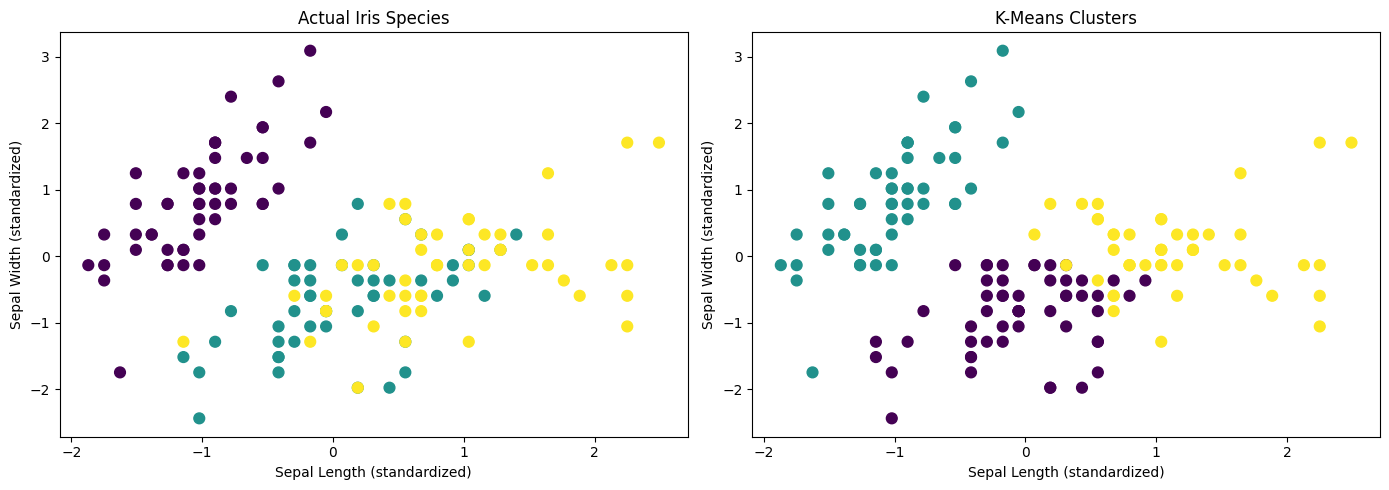

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual species
axes[0].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y,
    cmap="viridis",
    s=60
)

axes[0].set_title("Actual Iris Species")
axes[0].set_xlabel("Sepal Length (standardized)")
axes[0].set_ylabel("Sepal Width (standardized)")

# K-Means
axes[1].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=60
)

axes[1].set_title("K-Means Clusters")
axes[1].set_xlabel("Sepal Length (standardized)")
axes[1].set_ylabel("Sepal Width (standardized)")

plt.tight_layout()
plt.show()